# CSP Showcase — Graphics

All the plots of `02.B_CSP_showcase.ipynb`, drawn from the artifacts that notebook saves in
`results/runs/csp_showcase/<run_name_csp>/`. Run the CSP notebook first, then this one.

Figures are also saved as PNG in the `figures/` subfolder of the same run.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 100


def find_project_root() -> Path:
    """
    Find the repository root so paths work without further trouble.
    """
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "data").exists() and (candidate / "results").exists():
            return candidate
    raise FileNotFoundError("Could not find project root containing both `data/` and `results/`.")

# loading project root dir
PROJECT_ROOT = find_project_root()
RESULTS_DIR = PROJECT_ROOT / "results"


# --------- loading configuration environment ----------
# load .json config file (same file used by the pipeline notebooks)
CONFIG_PATH = RESULTS_DIR / "_config.json"
run_config = json.loads(CONFIG_PATH.read_text(encoding="utf-8"))

# input: the dataset and the CSP artifacts of the run to plot
CSP_SLOT_CSV = PROJECT_ROOT / run_config["csp_slot_csv"]
RUN_DIR = RESULTS_DIR / "runs" / "csp_showcase" / run_config["run_name_csp"]

# output: figures
FIGURE_DIR = RUN_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(CSP_SLOT_CSV)
disc_step_s = int(df['discretization_step_seconds'].iloc[0])
disc_step_h = disc_step_s / 3600

variables = pd.read_csv(RUN_DIR / "csp_variables.csv")
constraints = pd.read_csv(RUN_DIR / "csp_constraints.csv")
components = pd.read_csv(RUN_DIR / "csp_components.csv")

print(f"Loaded run: {RUN_DIR.resolve()}")
print({"slots": len(df), "satellites": len(variables), "components": len(components)})

Loaded run: D:\University\PoliMi\courses\SWE2\SWE2-research-project\results\runs\csp_showcase\latest_csp_run
{'slots': 2556, 'satellites': 95, 'components': 10}


## Visibility windows and candidate slots

The plot below shows the parent windows (shaded bars) and the candidate slots (ticks) on the time axis.

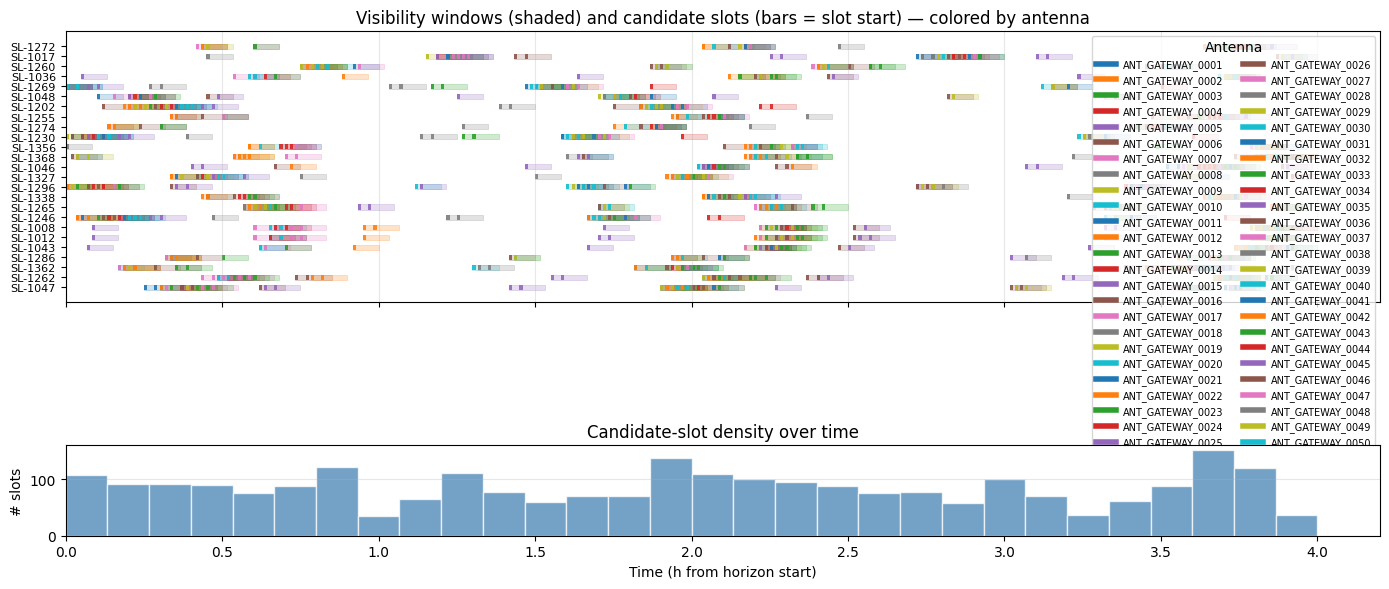

Slots per window: avg=1.27, max=2, min=1


In [2]:
# -------------------------------------------------------
# Show the satellites' vibility windows in the sky
# -------------------------------------------------------

# extract the start/end time of the original visibility window (and its serving antenna)
window_bounds = (
    df.groupby(['satellite_name', 'parent_window_id'])
    .agg(win_start=('start_time_hours', 'min'),
         win_end=('end_time_hours', 'max'),
         antenna_id=('antenna_id', 'first'))
    .reset_index()
)

# get the original visibility windows of the first
SAT_TO_DISPLAY = 25
top_sats = (
    df.groupby('satellite_name')['parent_window_id']
    .nunique().sort_values(ascending=False).head(SAT_TO_DISPLAY).index.tolist()
)

antennas = sorted(df['antenna_id'].unique())
cmap = plt.colormaps['tab10']
ant_color = {a: cmap(i % 10) for i, a in enumerate(antennas)}

fig, axes = plt.subplots(2, 1, figsize=(14, 6),
                         gridspec_kw={'height_ratios': [3, 1]}, sharex=True)

# --- upper: satellite visibility timeline, colored by serving antenna ---
ax = axes[0]
for i, sat in enumerate(top_sats):
    sat_wins  = window_bounds[window_bounds['satellite_name'] == sat]
    sat_slots = df[df['satellite_name'] == sat]

    # drow the original visibility window
    for _, row in sat_wins.iterrows():
        color = ant_color[row['antenna_id']]
        ax.barh(i, row['win_end'] - row['win_start'], left=row['win_start'],
                height=0.5, color=color, alpha=0.22, edgecolor=color, linewidth=0.7)

    # draw the discretized timeslot: a thin bar marking just the start of each slot
    for _, row in sat_slots.iterrows():
        color = ant_color[row['antenna_id']]
        ax.barh(i, disc_step_h * 0.3, left=row['start_time_hours'], height=0.5,
                color=color, alpha=0.9, edgecolor='none')

ax.set_yticks(range(len(top_sats)))
ax.set_yticklabels([s.replace('STARLINK-', 'SL-') for s in top_sats], fontsize=8)
ax.set_title('Visibility windows (shaded) and candidate slots (bars = slot start) — colored by antenna')
ax.grid(axis='x', alpha=0.3)
legend_handles = [plt.Line2D([0], [0], color=ant_color[a], lw=4, label=a) for a in antennas]
ax.legend(handles=legend_handles, loc='upper right', fontsize=7, ncol=2, title='Antenna')

# --- bottom: slot density over time ---
ax2 = axes[1]
bins = np.arange(0, df['start_time_hours'].max() + disc_step_h * 4, disc_step_h * 4)
ax2.hist(df['start_time_hours'], bins=bins, color='steelblue', alpha=0.75, edgecolor='white')
ax2.set_xlabel('Time (h from horizon start)')
ax2.set_ylabel('# slots')
ax2.set_title('Candidate-slot density over time')
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURE_DIR / 'visibility_windows.png', dpi=200)
plt.show()

spc = df.groupby('parent_window_id').size()
print(f'Slots per window: avg={spc.mean():.2f}, max={spc.max()}, min={spc.min()}')

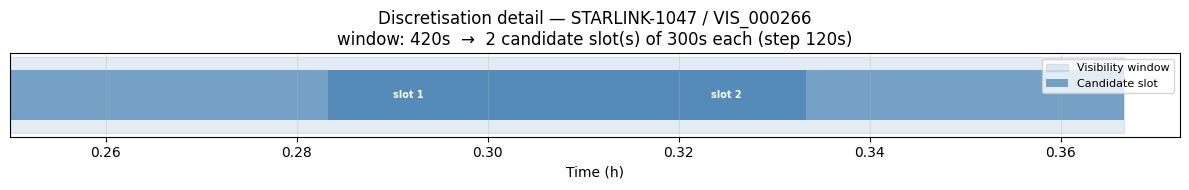

In [3]:
# -------------------------------------------------------
# Example of vibility window
# -------------------------------------------------------

# pick up some satellite as example
example_sat = df.groupby('satellite_name').size().idxmax()
ex = df[df['satellite_name'] == example_sat].sort_values('start_time_hours')
example_win = ex.groupby('parent_window_id').size().idxmax()
ex_win = ex[ex['parent_window_id'] == example_win]

win_s = ex_win['start_time_hours'].min()
win_e = ex_win['end_time_hours'].max()
slot_dur_s = int(ex_win['duration_seconds'].iloc[0])
slot_dur_h = slot_dur_s / 3600

# draw the original window
fig, ax = plt.subplots(figsize=(12, 2))
ax.barh(0, win_e - win_s, left=win_s, height=0.6, color='steelblue',
        alpha=0.15, edgecolor='steelblue', label='Visibility window')

# draw the derived candidate slots
for k, t_h in enumerate(ex_win['start_time_hours']):
    ax.barh(0, slot_dur_h, left=t_h, height=0.4,
            color='steelblue', alpha=0.7,
            label='Candidate slot' if k == 0 else '')
    ax.text(t_h + slot_dur_h / 2, 0, f'slot {k+1}',
            ha='center', va='center', fontsize=7, color='white', fontweight='bold')

ax.set_yticks([])
ax.set_xlabel('Time (h)')
ax.set_title(
    f'Discretisation detail — {example_sat} / {example_win}\n'
    f'window: {(win_e-win_s)*3600:.0f}s  →  {len(ex_win)} candidate slot(s) of {slot_dur_s}s each (step {disc_step_s}s)'
)
ax.legend(loc='upper right', fontsize=8)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'discretisation_detail.png', dpi=200)
plt.show()

### Problem Structure Before Preprocessing

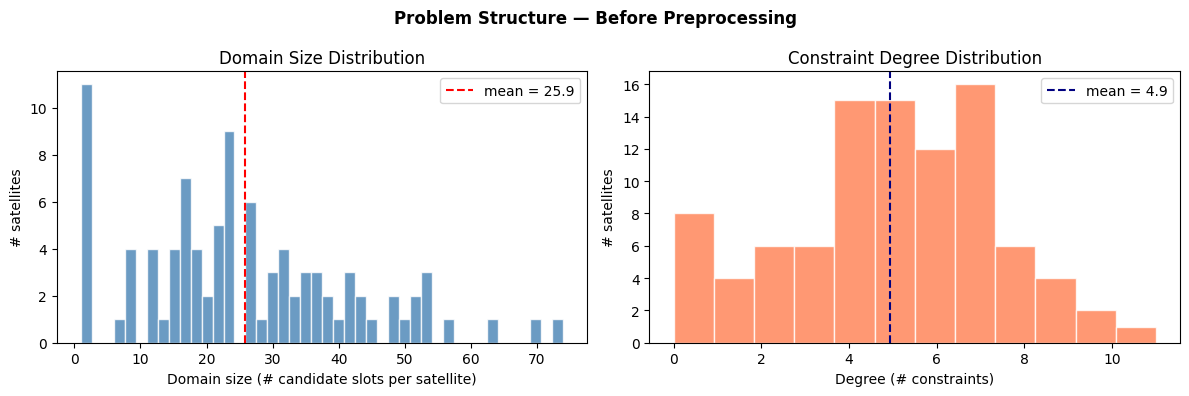

In [4]:
# just some barplots if the CSP elements distributions

domain_sizes = variables['domain_size_before']
degrees      = variables['degree_before']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(domain_sizes, bins=max(10, domain_sizes.nunique()),
             color='steelblue', alpha=0.8, edgecolor='white')
axes[0].axvline(domain_sizes.mean(), color='red', linestyle='--',
                label=f'mean = {domain_sizes.mean():.1f}')
axes[0].set_xlabel('Domain size (# candidate slots per satellite)')
axes[0].set_ylabel('# satellites')
axes[0].set_title('Domain Size Distribution')
axes[0].legend()

axes[1].hist(degrees, bins=max(10, degrees.nunique()),
             color='coral', alpha=0.8, edgecolor='white')
axes[1].axvline(degrees.mean(), color='navy', linestyle='--',
                label=f'mean = {degrees.mean():.1f}')
axes[1].set_xlabel('Degree (# constraints)')
axes[1].set_ylabel('# satellites')
axes[1].set_title('Constraint Degree Distribution')
axes[1].legend()

plt.suptitle('Problem Structure — Before Preprocessing', fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'problem_structure_before.png', dpi=200)
plt.show()

## Constraint graph

One node per satellite, one edge per constraint (two satellites competing for the same timeslot).
AC-3 prunes domains, which removes constraints and breaks the graph into smaller components.

In [5]:
# using networkx draw the problem's graph

# labels of the nodes, shared by both stages
var_labels = dict(zip(variables['var_id'], variables['name'].str.replace('STARLINK-', '', regex=False)))


def draw_csp_graph(stage: str, title: str, ax, seed: int = 42):
    """Draw the constraint graph of one stage ('before' or 'after' AC-3)."""
    G = nx.Graph()
    G.add_nodes_from(variables['var_id'])
    stage_edges = constraints[constraints['stage'] == stage]
    G.add_edges_from(zip(stage_edges['u_id'], stage_edges['v_id']))

    # color the nodes by connected component
    comps = list(nx.connected_components(G))
    cmap  = plt.colormaps['tab20']
    node_color = {n: cmap(ci / max(len(comps), 1))
                  for ci, comp in enumerate(comps)
                  for n in comp}

    pos = nx.spring_layout(G, seed=seed)
    nx.draw_networkx(
        G, pos, ax=ax,
        node_color=[node_color[n] for n in G.nodes()],
        node_size=[80 + 10 * G.degree(n) for n in G.nodes()],
        labels=var_labels, font_size=6,
        edge_color='gray', alpha=0.85, width=0.6,
    )
    ax.set_title(
        f'{title}\n'
        f'{G.number_of_nodes()} vars  ·  {G.number_of_edges()} constraints  ·  {len(comps)} component(s)'
    )
    ax.axis('off')


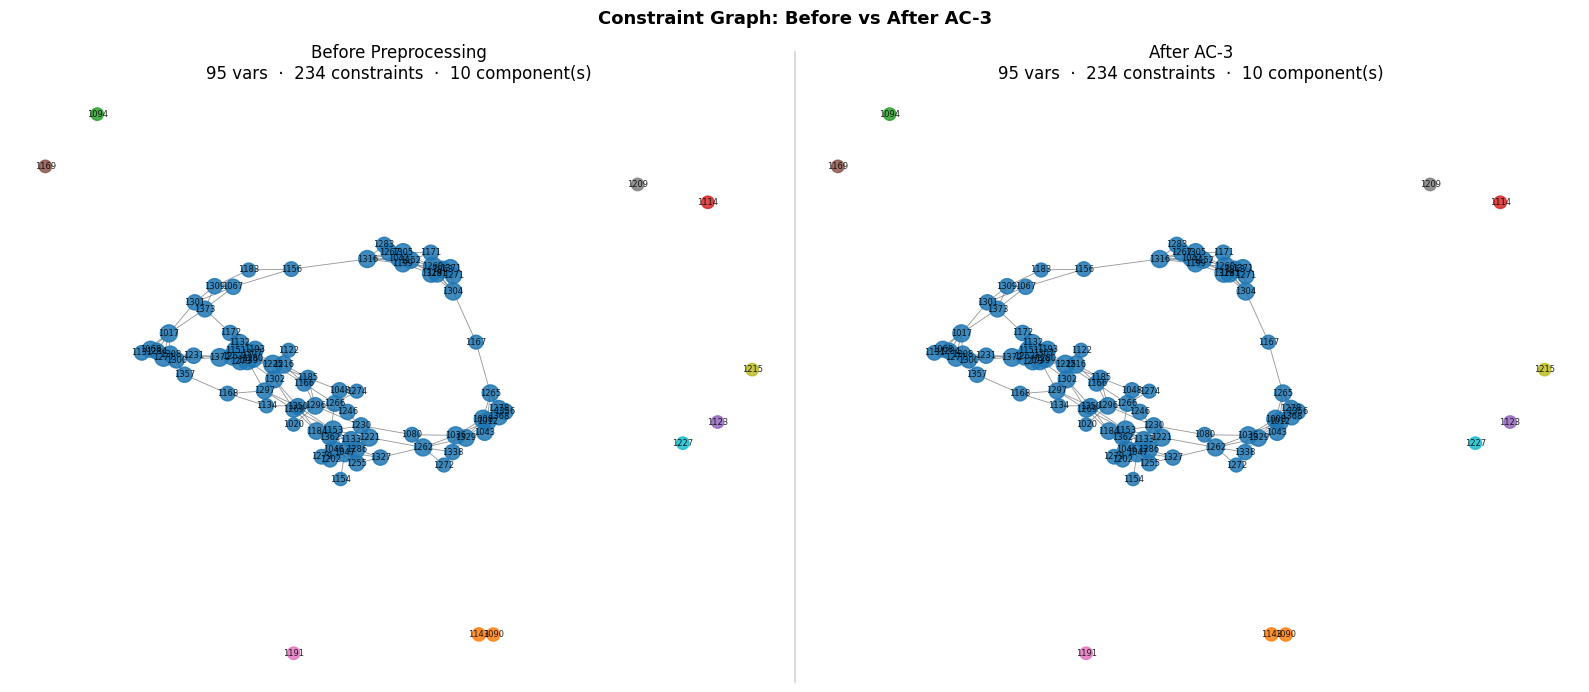

In [6]:
# Side-by-side constraint graphs
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
draw_csp_graph('before', 'Before Preprocessing', axes[0])
draw_csp_graph('after',  'After AC-3',           axes[1])
plt.suptitle('Constraint Graph: Before vs After AC-3', fontsize=13, fontweight='bold')
plt.tight_layout()
fig.add_artist(plt.Line2D([0.5, 0.5], [0.02, 0.92], color='lightgray', linewidth=1.2))
plt.savefig(FIGURE_DIR / 'constraint_graph_before_after.png', dpi=200)
plt.show()

## Connected components after AC-3

Each component is an independent sub-problem, translated into its own QUBO.

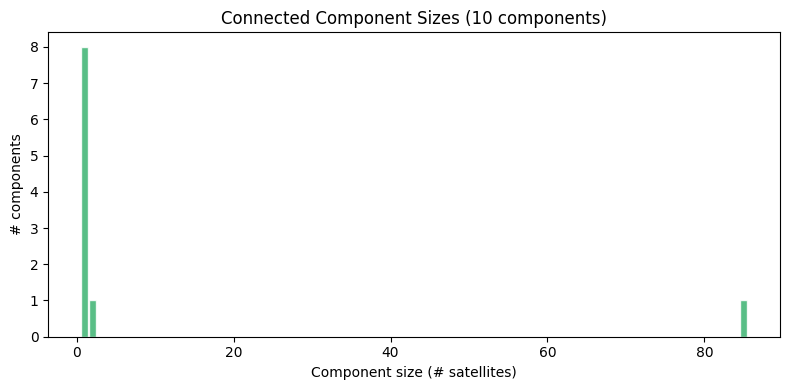

In [7]:
# Component-size distribution
fig, axes = plt.subplots(1, 1, figsize=(8, 4))

size_counts = components['num_vars'].value_counts().sort_index()
axes.bar(size_counts.index, size_counts.values,
         color='mediumseagreen', alpha=0.85, edgecolor='white')
axes.set_xlabel('Component size (# satellites)')
axes.set_ylabel('# components')
axes.set_title(f'Connected Component Sizes ({len(components)} components)')
if size_counts.index.max() <= 20:
    axes.set_xticks(size_counts.index)

plt.tight_layout()
plt.savefig(FIGURE_DIR / 'component_sizes.png', dpi=200)
plt.show()